# Interpolation (Lagrange, Newton) and ODE schemes (Euler, Heun)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [23]:
## Polynome de base Lagrange
def Lagrange(f,a,b,n):
    x=np.linspace(a,b,n+1)
    print(x)
    X=np.poly1d([1,0])
    
    P=0
    for i in range(n+1):
        Li=1
        for j in range(n+1):
            if(i==j):
                continue;
            else:
                Li=Li*(X-x[j])/(x[i]-x[j])
        P=P+Li*f(x[i])
    return P

In [24]:
## Polynome de base Newton
# divided differnce matrix
def divided_diff(x, y):
    '''
    function to calculate the divided
    differences table
    '''
    n = len(y)
    coef = np.zeros([n, n])
    # the first column is y
    coef[:,0] = y
    
    for j in range(1,n):
        for i in range(j,n):
            coef[i][j] =(coef[i][j-1] - coef[i-1][j-1]) / (x[i]-x[i-j]) ;    
    return coef
def newton_poly(coef, x):
    X=np.poly1d([1,0])
    n = len(x)
    PP = float(coef[0,0])*np.poly1d([0,1]);
    p=1
    for k in range(1,n):
        p=(X -x[k-1])*p;
        PP =PP+ coef[k,k]*p;
    return PP
def newton_interpolation(f,a,b,n):
    x=np.linspace(a,b,n+1);
    div_co=divided_diff(x, f(x));
    P=newton_poly(div_co,x);
    return P

[-5.         -1.66666667  1.66666667  5.        ]
[-5. -3. -1.  1.  3.  5.]
[-5.   -3.75 -2.5  -1.25  0.    1.25  2.5   3.75  5.  ]


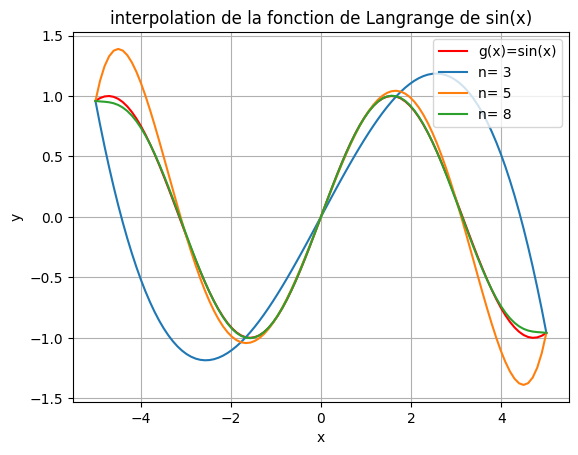

In [25]:
# plot Langrange interpolation
a=-5
b=5
g=np.sin
xp=np.linspace(a,b,100);
Pg=[Lagrange(g,a,b,n) for n in [3,5,8]]
plt.plot(xp,g(xp),'r');
for n in range(3):
    plt.plot(xp,np.polyval(Pg[n],xp))

plt.title("interpolation de la fonction de Langrange de sin(x)")


leg=["g(x)=sin(x)"]
for n in [3,5,8]:
    leg=leg+["n= "+str(n)]
    
plt.xlabel('x')
plt.ylabel('y')
plt.legend(leg)
plt.grid()
plt.show()

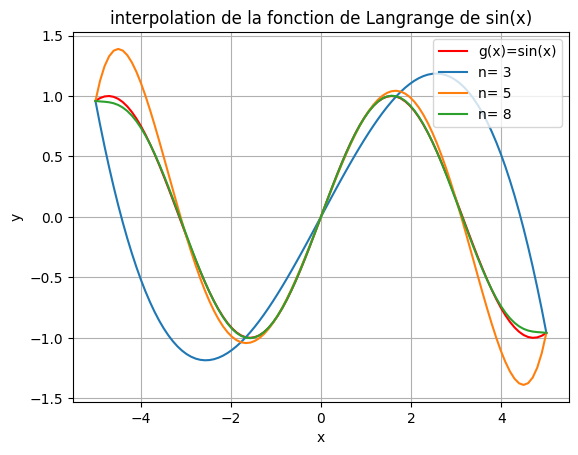

In [26]:
# plot Newton interpolation
g=np.sin
PN=[newton_interpolation(g,a,b,n) for n in [3,5,8]]
xp=np.linspace(-5,5,100);
plt.plot(xp,g(xp),'r');
for n in range(3):
    plt.plot(xp,np.polyval(PN[n],xp))

plt.title("interpolation de la fonction de Langrange de sin(x)")


leg=["g(x)=sin(x)"]
for n in [3,5,8]:
    leg=leg+["n= "+str(n)]
    
plt.xlabel('x')
plt.ylabel('y')
plt.legend(leg)
plt.grid()
plt.show()

In [ ]:
## Les equa diff
def EulerExpl(F, y0, T, N):
    Y = np.zeros(N+1)
    dt = T/N
    Y[0] = y0
    for n in range(N):
        Y[n+1] = Y[n] + dt*F(Y[n])
    return Y
def Heun(F, y0, T, N):
    Y = np.zeros(N+1)
    dt = T/N
    Y[0] = y0
    for n in range(N):
        Y[n+1] = Y[n] + .5*dt*(F(Y[n]) + F(Y[n] + dt*F(Y[n])))
    return Y

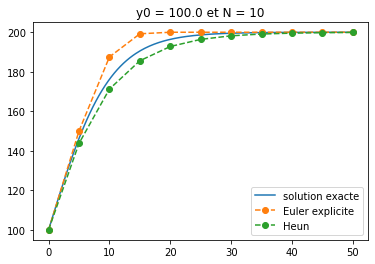

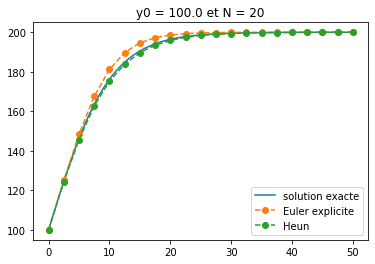

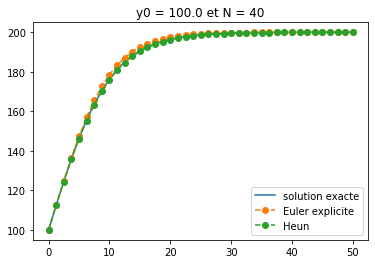

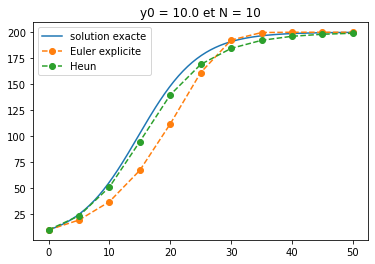

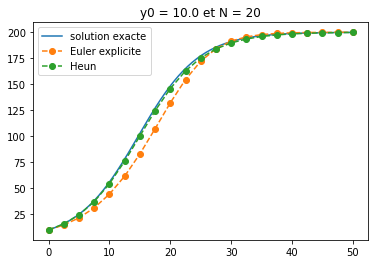

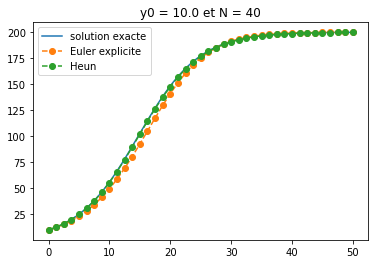

In [ ]:
# Modèle de croissance logistique
a, b, T = .2, .001, 50
K = a/b
F = lambda y: b*y*(K-y)

liste_y0 = (.5*K, .05*K)
liste_N = (10, 20, 40)

for y0 in liste_y0:
    # discrétisation fine de la solution exacte
    t_fin = np.linspace(0, T, 200)
    Yex = a*y0/(b*y0 + (a-b*y0)*np.exp(-a*t_fin))
    for N in liste_N:
        # représentation graphique de la solution exacte
        plt.plot(t_fin, Yex, label="solution exacte")
        # calcul des solutions approchées
        Yee = EulerExpl(F, y0, T, N)
        Yhe = Heun(F, y0, T, N)
        # représentation graphique des solutions approchées
        tn = np.linspace(0, T, N+1)
        plt.plot(tn, Yee, 'o--', label="Euler explicite")
        plt.plot(tn, Yhe, 'o--', label="Heun")
        plt.legend()
        plt.title(f"y0 = {y0} et N = {N}")
        plt.show()

## Malthusian growth: exact solution, Euler and Heun schemes

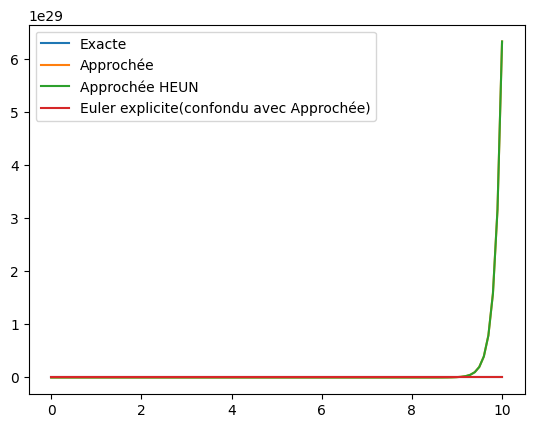

In [84]:
import numpy as np
import matplotlib.pyplot as plt

                #Déclaration des variables
P0 = 1
b=10
c=30
x = np.linspace(0, b, c)
a = 0.3
N=100 #nombre de discrétisation
DELTAt = N/c
F= lambda y: y*a #Fonction F
aa=0

                #Modèle de Maltheusien

def solution_exacte (a, P0,x):
    return P0*(np.exp(a*x))

P1 = solution_exacte(a,P0,x)


                #Approché

def solution_approchée(a,DELTAt, N):
    P = np.zeros(N)
    P[0]=P0
    for n in range(1,N):
        P[n] = (1+a*DELTAt)*P[n-1]
    return P

P2 = solution_approchée(a,DELTAt, N)

                #Heun

def solution_HEUN (dt, N,a):
    Y = np.zeros(N)
    Y[0]=P0
    for n in range(1,N):
        Y[n] = Y[n-1]+(dt/2)*(F(Y[n-1]+dt*F(Y[n-1])))
    return Y

Y1 = solution_HEUN (DELTAt, N, a)

            #Euler Explicite

def solution_explicite(F,P0,aa,b,N):
    Y = np.zeros(N+1)
    T=b-aa
    dt=T/N
    Y[0]=P0
    for n in range(N):
        Y[n+1] = Y[n] + dt * F(Y[n])
    return Y
    
Y2 = solution_explicite(F,P0,aa,b,N)


            #print



x1 = np.linspace(0, b, c)
x2 = np.linspace(0, b, N)
x3 = np.linspace(0, b, N)
x4 = np.linspace(0, b, N+1)

plt.plot(x1, P1, label='Exacte')
plt.plot(x2, P2, label='Approchée')
plt.plot(x3, Y1, label='Approchée HEUN')
plt.plot(x4, Y2, label='Euler explicite(confondu avec Approchée)')
plt.legend()
plt.show()


